# Análisis de Componentes Principales (PCA) con Iris

En esta práctica se estandarizan las cuatro mediciones numéricas de `load_iris`, se obtiene la descomposición propia de su matriz de covarianza y se proyectan las observaciones sobre los dos componentes principales. Las etiquetas se usan únicamente para colorear el gráfico, no para calcular el PCA.

## 1. Cargar los datos e importar las herramientas

La media y la desviación estándar se calcularán explícitamente con NumPy. Se usa `PCA` de scikit-learn solo como referencia para comprobar la descomposición calculada manualmente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X = iris.data.astype(float)  # Solo las cuatro variables numéricas
y = iris.target             # Etiquetas reservadas para el gráfico
n, d = X.shape

print(f"Observaciones: {n}; variables: {d}")
print("Variables:", iris.feature_names)
print("Clases:", iris.target_names)

Observaciones: 150; variables: 4
Variables: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa' 'versicolor' 'virginica']


## 2. Calcular media, desviación estándar y estandarizar

Se usa la desviación estándar poblacional (`ddof=0`) para que las columnas estandarizadas tengan desviación 1. La matriz de covarianza que calcularemos después usa la convención muestral de `np.cov`.

In [2]:
media = np.mean(X, axis=0)
std = np.std(X, axis=0, ddof=0)
X_std = (X - media) / std

print("Media original:", media)
print("Desviación estándar original:", std)
print("Media estandarizada:", np.mean(X_std, axis=0))
print("Desviación estandarizada:", np.std(X_std, axis=0, ddof=0))

assert np.allclose(np.mean(X_std, axis=0), 0, atol=1e-12)
assert np.allclose(np.std(X_std, axis=0, ddof=0), 1, atol=1e-12)

Media original: [5.84333333 3.05733333 3.758      1.19933333]
Desviación estándar original: [0.82530129 0.43441097 1.75940407 0.75969263]
Media estandarizada: [-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]
Desviación estandarizada: [1. 1. 1. 1.]


## 3. Matriz de covarianza

Cada fila de `X_std` es una observación y cada columna una variable, por eso se usa `rowvar=False`. La matriz debe ser cuadrada, de tamaño `(d, d)`, y simétrica.

In [3]:
cov = np.cov(X_std, rowvar=False)

print("Matriz de covarianza:\n", cov)
print("Tamaño:", cov.shape)
print("¿Es simétrica?:", np.allclose(cov, cov.T))

assert cov.shape == (d, d)
assert np.allclose(cov, cov.T)

Matriz de covarianza:
 [[ 1.00671141 -0.11835884  0.87760447  0.82343066]
 [-0.11835884  1.00671141 -0.43131554 -0.36858315]
 [ 0.87760447 -0.43131554  1.00671141  0.96932762]
 [ 0.82343066 -0.36858315  0.96932762  1.00671141]]
Tamaño: (4, 4)
¿Es simétrica?: True


## 4. Eigenvalores y eigenvectores

Como la matriz de covarianza es simétrica, `np.linalg.eigh` es apropiada. Se ordenan los componentes de mayor a menor eigenvalor: cada eigenvector indica una dirección y su eigenvalor la varianza explicada en esa dirección.

In [4]:
eigenvalores, eigenvectores = np.linalg.eigh(cov)
orden = np.argsort(eigenvalores)[::-1]
eigenvalores = eigenvalores[orden]
eigenvectores = eigenvectores[:, orden]

varianza_explicada = eigenvalores / np.sum(eigenvalores)
print("Eigenvalores ordenados:\n", eigenvalores)
print("Eigenvectores ordenados (columnas):\n", eigenvectores)
print("Proporción de varianza explicada:\n", varianza_explicada)
print("Varianza acumulada con 2 componentes:", varianza_explicada[:2].sum())

Eigenvalores ordenados:
 [2.93808505 0.9201649  0.14774182 0.02085386]
Eigenvectores ordenados (columnas):
 [[-0.52106591  0.37741762  0.71956635  0.26128628]
 [ 0.26934744  0.92329566 -0.24438178 -0.12350962]
 [-0.5804131   0.02449161 -0.14212637 -0.80144925]
 [-0.56485654  0.06694199 -0.63427274  0.52359713]]
Proporción de varianza explicada:
 [0.72962445 0.22850762 0.03668922 0.00517871]
Varianza acumulada con 2 componentes: 0.9581320720000165


## 5. Comparación con `sklearn.decomposition.PCA`

La orientación (signo) de un eigenvector puede invertirse sin cambiar la dirección que representa. Por eso se alinean los signos antes de comparar los eigenvectores con `np.allclose`.

In [5]:
pca_referencia = PCA(n_components=d).fit(X_std)
componentes_referencia = pca_referencia.components_.T
signos = np.where(np.sum(eigenvectores * componentes_referencia, axis=0) < 0, -1, 1)
eigenvectores_alineados = eigenvectores * signos

print("Eigenvalores coinciden:", np.allclose(eigenvalores, pca_referencia.explained_variance_))
print("Eigenvectores coinciden tras alinear signos:", np.allclose(eigenvectores_alineados, componentes_referencia))

assert np.allclose(eigenvalores, pca_referencia.explained_variance_)
assert np.allclose(eigenvectores_alineados, componentes_referencia)

Eigenvalores coinciden: True
Eigenvectores coinciden tras alinear signos: True


## 6. Proyección y gráfico de los dos primeros componentes

Se proyectan los datos estandarizados en las dos direcciones con mayor varianza. Las clases reales solo se utilizan para identificar los puntos en el gráfico.

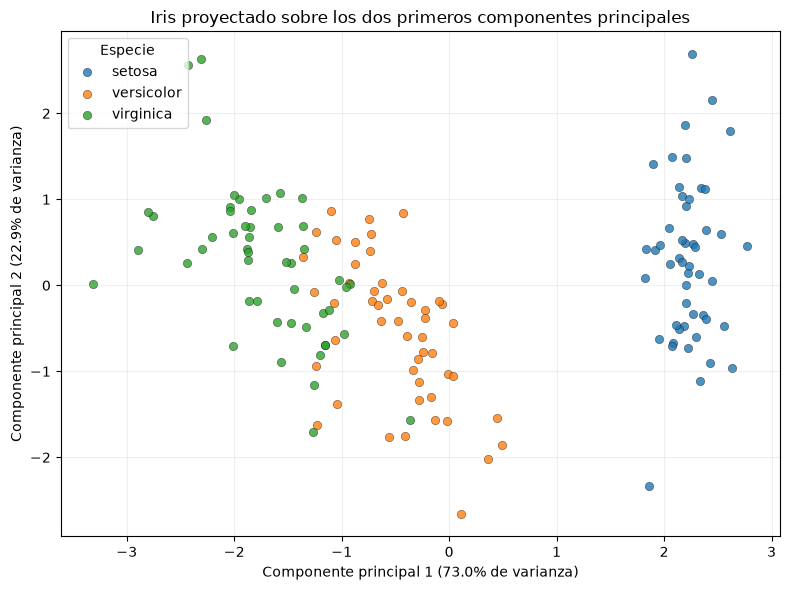

In [6]:
X_pca = X_std @ eigenvectores[:, :2]

fig, ax = plt.subplots(figsize=(8, 6))
for clase, nombre in enumerate(iris.target_names):
    seleccion = y == clase
    ax.scatter(
        X_pca[seleccion, 0],
        X_pca[seleccion, 1],
        label=nombre,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.3,
    )

ax.set_title("Iris proyectado sobre los dos primeros componentes principales")
ax.set_xlabel(f"Componente principal 1 ({varianza_explicada[0]:.1%} de varianza)")
ax.set_ylabel(f"Componente principal 2 ({varianza_explicada[1]:.1%} de varianza)")
ax.legend(title="Especie")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Conclusiones

- **¿Se separan bien las especies?** Setosa suele quedar claramente separada de las otras dos especies. Versicolor y virginica presentan cierta separación, pero también se traslapan; por lo tanto, los dos componentes no separan perfectamente las tres clases.
- **¿Qué significa conservar solo dos componentes?** La proyección conserva las direcciones con mayor varianza y, en este conjunto estandarizado, aproximadamente el 95.8% de la varianza total. Se reduce de cuatro dimensiones a dos para visualizar los datos, pero se descarta la variación de los componentes restantes. La varianza conservada no equivale necesariamente a conservar toda la información útil para distinguir clases.